# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut: Joko_05_5025251223_TugasDatabaseTendik
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

 


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('Telco Customer Churn.csv')
display(df.info())
df

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


<Axes: xlabel='Churn'>

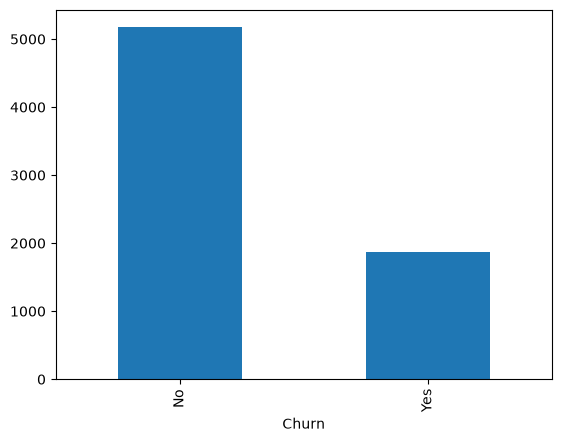

In [3]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
df['Churn'].value_counts().plot(kind='bar')

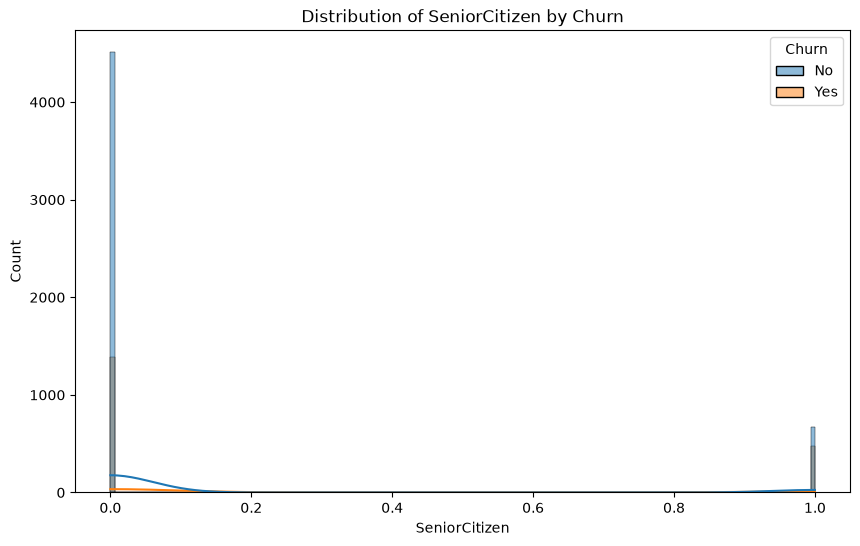

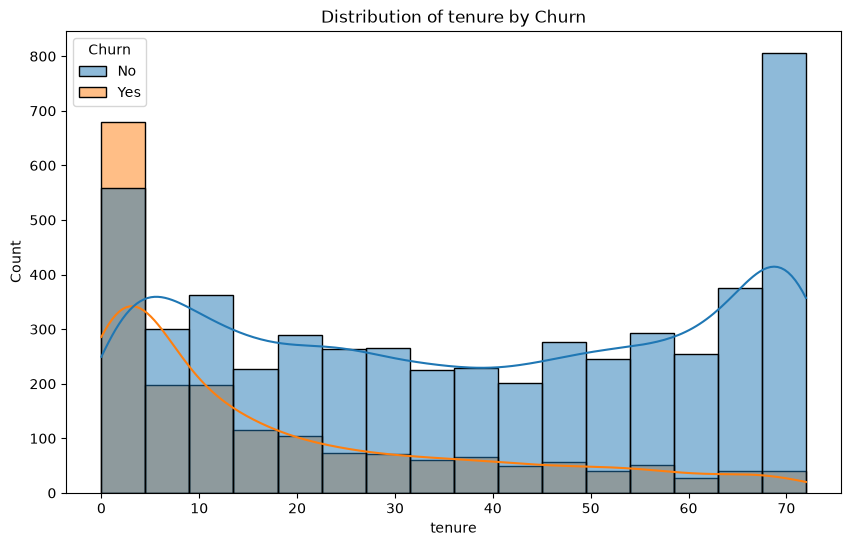

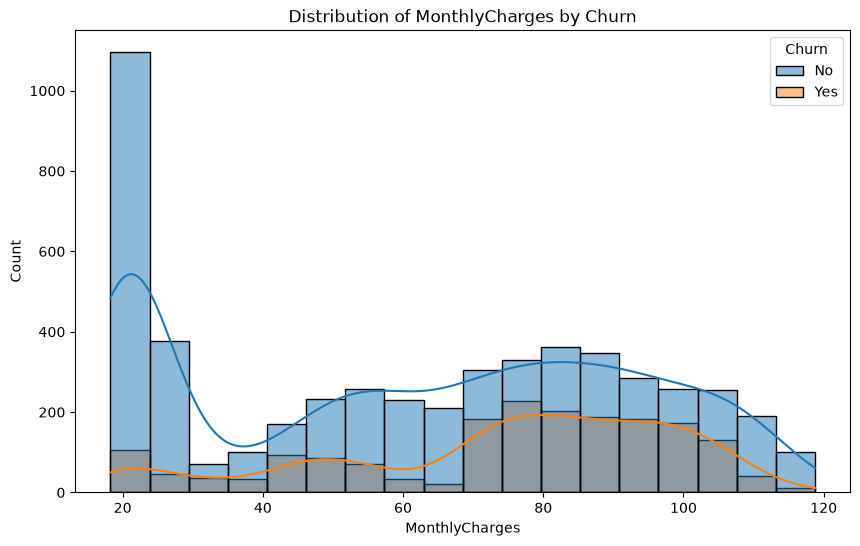

<Axes: >

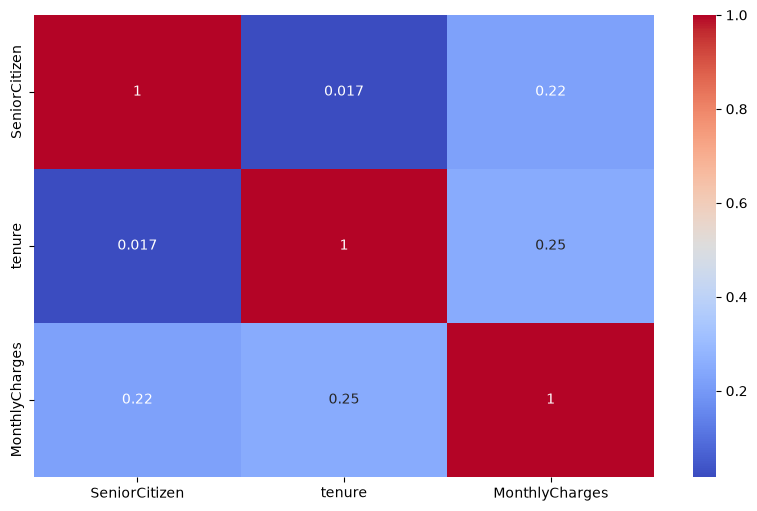

In [4]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.
import seaborn as sns

numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df, x=feature, hue='Churn', kde=True)
    plt.title(f'Distribution of {feature} by Churn')
    plt.show()

plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap='coolwarm')

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [5]:
print(f"duplicate: {df.duplicated().sum()}")
print(f"missing value: {df.isnull().sum().sum()}")


duplicate: 0
missing value: 0


In [6]:
df_cleaned = df.copy()

In [7]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
# Loaded variable 'df' from kernel state

# One-hot encode columns: 'gender', 'InternetService' and 13 other columns

import pandas as pd
for column in ['gender', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MultipleLines', 'Partner', 'Dependents', 'PhoneService']:
    insert_loc = df_cleaned.columns.get_loc(column)
    df_cleaned = pd.concat([df_cleaned.iloc[:,:insert_loc], pd.get_dummies(df_cleaned.loc[:, [column]], dummy_na=True), df_cleaned.iloc[:,insert_loc+1:]], axis=1)

# Replace all instances of "No" with "0" in column: 'Churn'
df_cleaned['Churn'] = df_cleaned['Churn'].str.replace("No", "0", case=False, regex=False)

# Replace all instances of "Yes" with "1" in column: 'Churn'
df_cleaned['Churn'] = df_cleaned['Churn'].str.replace("Yes", "1", case=False, regex=False)
df_cleaned['Churn'] = df_cleaned['Churn'].astype(int)


#convert to float
df_cleaned['TotalCharges'] = pd.to_numeric(df_cleaned['TotalCharges'], errors='coerce')

In [8]:
df_cleaned = df_cleaned.dropna(subset=['TotalCharges'])

In [9]:
df_cleaned.head()

,customerID,gender_Female,gender_Male,gender_nan,SeniorCitizen,Partner_No,Partner_Yes,Partner_nan,Dependents_No,Dependents_Yes,...,PaperlessBilling_Yes,PaperlessBilling_nan,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,PaymentMethod_nan,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,True,False,False,0,False,True,False,True,False,...,True,False,False,False,True,False,False,29.85,29.85,0
1,5575-GNVDE,False,True,False,0,True,False,False,True,False,...,False,False,False,False,False,True,False,56.95,1889.50,0
2,3668-QPYBK,False,True,False,0,True,False,False,True,False,...,True,False,False,False,False,True,False,53.85,108.15,1
3,7795-CFOCW,False,True,False,0,True,False,False,True,False,...,False,False,True,False,False,False,False,42.30,1840.75,0
4,9237-HQITU,True,False,False,0,True,False,False,True,False,...,True,False,False,False,True,False,False,70.70,151.65,1


In [10]:
df_cleaned.drop(columns=['customerID'], inplace=True)

In [11]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
target = 'Churn'
X_train, X_test, y_train, y_test = train_test_split(df_cleaned.drop(columns=target), df_cleaned[target], test_size=0.2, random_state=42, stratify=df_cleaned['Churn'])


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [12]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
from sklearn.preprocessing import StandardScaler
Scaler = StandardScaler()
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
X_train[numeric_features] = Scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = Scaler.transform(X_test[numeric_features])

# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [13]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).
model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42, activation='relu')
model.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(10,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [14]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

y_pred = model.predict(X_test)
y_pred_baseline = y_pred
model_baseline = model

# Simpan metrik model baseline
metrics_baseline = {
    'Eksperimen': '3.1 Baseline',
    'Arsitektur': '(10,)',
    'Aktivasi': 'relu',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
}

classification_rep = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()
display(classification_rep)
print("Metrik Baseline Tersimpan:", metrics_baseline)

,precision,recall,f1-score,support
0,0.836643,0.897386,0.865950,1033.00000
1,0.645485,0.516043,0.573551,374.00000
accuracy,0.796020,0.796020,0.796020,0.79602
macro avg,0.741064,0.706715,0.719751,1407.00000
weighted avg,0.785830,0.796020,0.788227,1407.00000


Metrik Baseline Tersimpan: {'Eksperimen': '3.1 Baseline', 'Arsitektur': '(10,)', 'Aktivasi': 'relu', 'Accuracy': 0.7960199004975125, 'Precision': 0.6454849498327759, 'Recall': 0.516042780748663, 'F1-Score': 0.5735512630014858}


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [15]:
# Latih beberapa model MLPClassifier dengan arsitektur yang sama, tetapi activation berbeda:
# 'relu', 'tanh', dan 'logistic'.
# Gunakan hyperparameter lain yang sama (hidden_layer_sizes, max_iter, random_state) agar perbandingan adil.

accuracy_scores = {}
models_activation = {}
metrics_activation_list = []

for activation in ['relu', 'tanh', 'logistic']:
    model_act = MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42, activation=activation)
    model_act.fit(X_train, y_train)
    y_pred_act = model_act.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred_act)
    prec = precision_score(y_test, y_pred_act)
    rec = recall_score(y_test, y_pred_act)
    f1 = f1_score(y_test, y_pred_act)
    
    accuracy_scores[activation] = acc
    models_activation[activation] = model_act
    
    metrics_activation_list.append({
        'Activation Function': activation,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })
    print(f"Activation: {activation:8s} | Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-Score: {f1:.4f}")

# Simpan dan tampilkan tabel perbandingan metrik untuk setiap fungsi aktivasi
df_perbandingan = pd.DataFrame(metrics_activation_list)
display(df_perbandingan)

Activation: relu     | Accuracy: 0.7960 | Precision: 0.6455 | Recall: 0.5160 | F1-Score: 0.5736


/home/data/kuliah/rka/ML/Asset/Modul-Praktikum-ML-RKA/4. SVM, ANN/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Activation: tanh     | Accuracy: 0.7932 | Precision: 0.6426 | Recall: 0.5000 | F1-Score: 0.5624


Activation: logistic | Accuracy: 0.7967 | Precision: 0.6447 | Recall: 0.5241 | F1-Score: 0.5782


/home/data/kuliah/rka/ML/Asset/Modul-Praktikum-ML-RKA/4. SVM, ANN/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Activation Function,Accuracy,Precision,Recall,F1-Score
0,relu,0.796020,0.645485,0.516043,0.573551
1,tanh,0.793177,0.642612,0.500000,0.562406
2,logistic,0.796731,0.644737,0.524064,0.578171


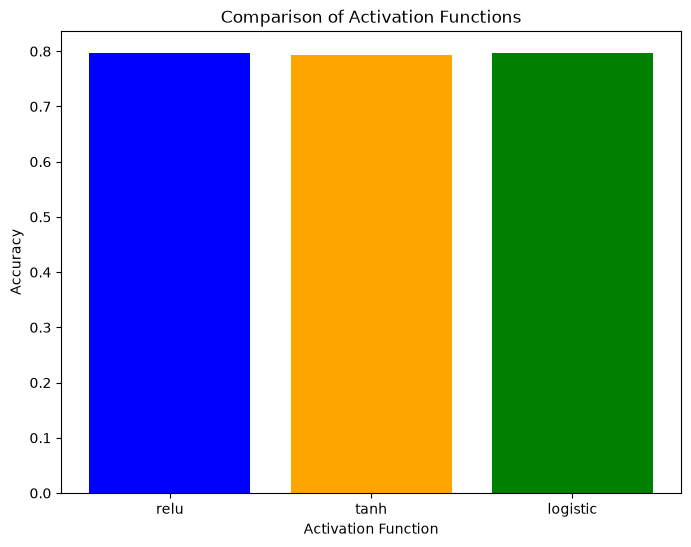

Tabel Perbandingan Metrik Evaluasi Fungsi Aktivasi:


,Activation Function,Accuracy,Precision,Recall,F1-Score
0,relu,0.796020,0.645485,0.516043,0.573551
1,tanh,0.793177,0.642612,0.500000,0.562406
2,logistic,0.796731,0.644737,0.524064,0.578171



Confusion Matrix (Model Aktivasi Terbaik - logistic):
[[925 108]
 [178 196]]

================== whos the winneeeerr   ==================
Activation Function: logistic, Accuracy: 0.7967 dengan selisih 0.0036 dibandingkan dengan activation function terendah


In [16]:
# Hitung dan bandingkan akurasi test set dari ketiga fungsi aktivasi tersebut.
# Sajikan dalam tabel perbandingan.

plt.figure(figsize=(8, 6))
plt.bar(accuracy_scores.keys(), accuracy_scores.values(), color=['blue', 'orange', 'green'], tick_label=accuracy_scores.keys())
plt.title('Comparison of Activation Functions')
plt.xlabel('Activation Function')
plt.ylabel('Accuracy')
plt.show()

print("Tabel Perbandingan Metrik Evaluasi Fungsi Aktivasi:")
display(df_perbandingan)

best_act = max(accuracy_scores, key=accuracy_scores.get)
print(f"\nConfusion Matrix (Model Aktivasi Terbaik - {best_act}):")
conf_matrix = confusion_matrix(y_test, models_activation[best_act].predict(X_test))
print(conf_matrix)

print("\n================== whos the winneeeerr   ==================")
print(f"Activation Function: {best_act}, Accuracy: {max(accuracy_scores.values()):.4f} dengan selisih {max(accuracy_scores.values()) - min(accuracy_scores.values()):.4f} dibandingkan dengan activation function terendah")

## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [17]:
# Latih beberapa model MLPClassifier dengan variasi hidden_layer_sizes,
# misalnya (2,), (5,), (10,), (50,), (100, 50).
# Gunakan activation terbaik dari hasil eksperimen 3.2, dan hyperparameter lain yang sama.
best_activation = max(accuracy_scores, key=accuracy_scores.get)
accuracy_scores_experimentlayer = {}
train_accuracy_scores = {}
models_architecture = {}
metrics_architecture_list = []

for hidden_layer in [(2,), (5,), (10,), (50,), (100, 50)]:
    model = MLPClassifier(
        hidden_layer_sizes=hidden_layer, 
        max_iter=300, 
        random_state=42, 
        activation=best_activation
    )
    model.fit(X_train, y_train)
    
    y_pred_test = model.predict(X_test)
    y_pred_train = model.predict(X_train)
    
    acc_test = accuracy_score(y_test, y_pred_test)
    acc_train = accuracy_score(y_train, y_pred_train)
    prec_test = precision_score(y_test, y_pred_test)
    rec_test = recall_score(y_test, y_pred_test)
    f1_test = f1_score(y_test, y_pred_test)

    accuracy_scores_experimentlayer[hidden_layer] = acc_test
    train_accuracy_scores[hidden_layer] = acc_train
    models_architecture[hidden_layer] = model
    
    metrics_architecture_list.append({
        'Hidden Layer Sizes': str(hidden_layer),
        'Train Accuracy': acc_train,
        'Test Accuracy': acc_test,
        'Precision': prec_test,
        'Recall': rec_test,
        'F1-Score': f1_test
    })
    
    print(f"Hidden Layer Sizes: {str(hidden_layer):12s} | Train Acc: {acc_train:.4f} | Test Acc: {acc_test:.4f} | Prec: {prec_test:.4f} | Rec: {rec_test:.4f} | F1: {f1_test:.4f}")

Hidden Layer Sizes: (2,)         | Train Acc: 0.8030 | Test Acc: 0.7953 | Prec: 0.6327 | Rec: 0.5481 | F1: 0.5874


Hidden Layer Sizes: (5,)         | Train Acc: 0.8073 | Test Acc: 0.7953 | Prec: 0.6361 | Rec: 0.5374 | F1: 0.5826


/home/data/kuliah/rka/ML/Asset/Modul-Praktikum-ML-RKA/4. SVM, ANN/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Hidden Layer Sizes: (10,)        | Train Acc: 0.8146 | Test Acc: 0.7967 | Prec: 0.6447 | Rec: 0.5241 | F1: 0.5782


Hidden Layer Sizes: (50,)        | Train Acc: 0.8078 | Test Acc: 0.7967 | Prec: 0.6310 | Rec: 0.5668 | F1: 0.5972


Hidden Layer Sizes: (100, 50)    | Train Acc: 0.8116 | Test Acc: 0.7939 | Prec: 0.6312 | Rec: 0.5401 | F1: 0.5821


In [18]:
# Hitung akurasi pada train set dan test set untuk setiap arsitektur yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

df_architecture_metrics = pd.DataFrame(metrics_architecture_list)
display(df_architecture_metrics)

,Hidden Layer Sizes,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,"(2,)",0.803022,0.795309,0.632716,0.548128,0.587393
1,"(5,)",0.807289,0.795309,0.636076,0.537433,0.582609
2,"(10,)",0.814578,0.796731,0.644737,0.524064,0.578171
3,"(50,)",0.807822,0.796731,0.630952,0.566845,0.597183
4,"(100, 50)",0.811556,0.793888,0.631250,0.540107,0.582133


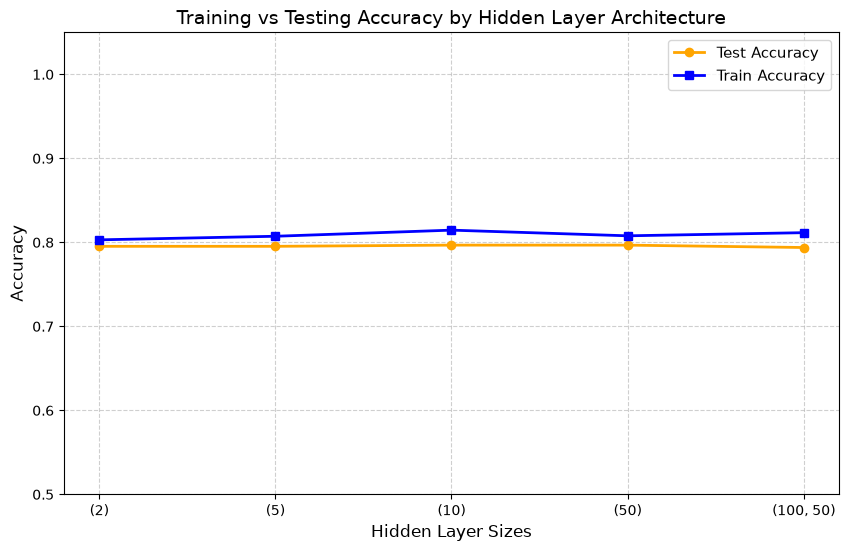

In [19]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).\


plt.figure(figsize=(10, 6))

# Merapikan label sumbu X (mengubah tuple (2,) menjadi string "(2)")
x_labels = [str(k).replace(',)', ')') for k in accuracy_scores_experimentlayer.keys()]

# Plot Akurasi Testing
plt.plot(
    x_labels, 
    list(accuracy_scores_experimentlayer.values()), 
    marker='o', 
    label='Test Accuracy', 
    color='orange',
    linewidth=2
)

# Plot Akurasi Training (BARU)
plt.plot(
    x_labels, 
    list(train_accuracy_scores.values()), 
    marker='s', 
    label='Train Accuracy', 
    color='blue',
    linewidth=2
)

# Pengaturan Chart
plt.title('Training vs Testing Accuracy by Hidden Layer Architecture', fontsize=14)
plt.xlabel('Hidden Layer Sizes', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0.5, 1.05) # Sesuaikan batas Y agar garis tidak menempel di pinggir

plt.show()

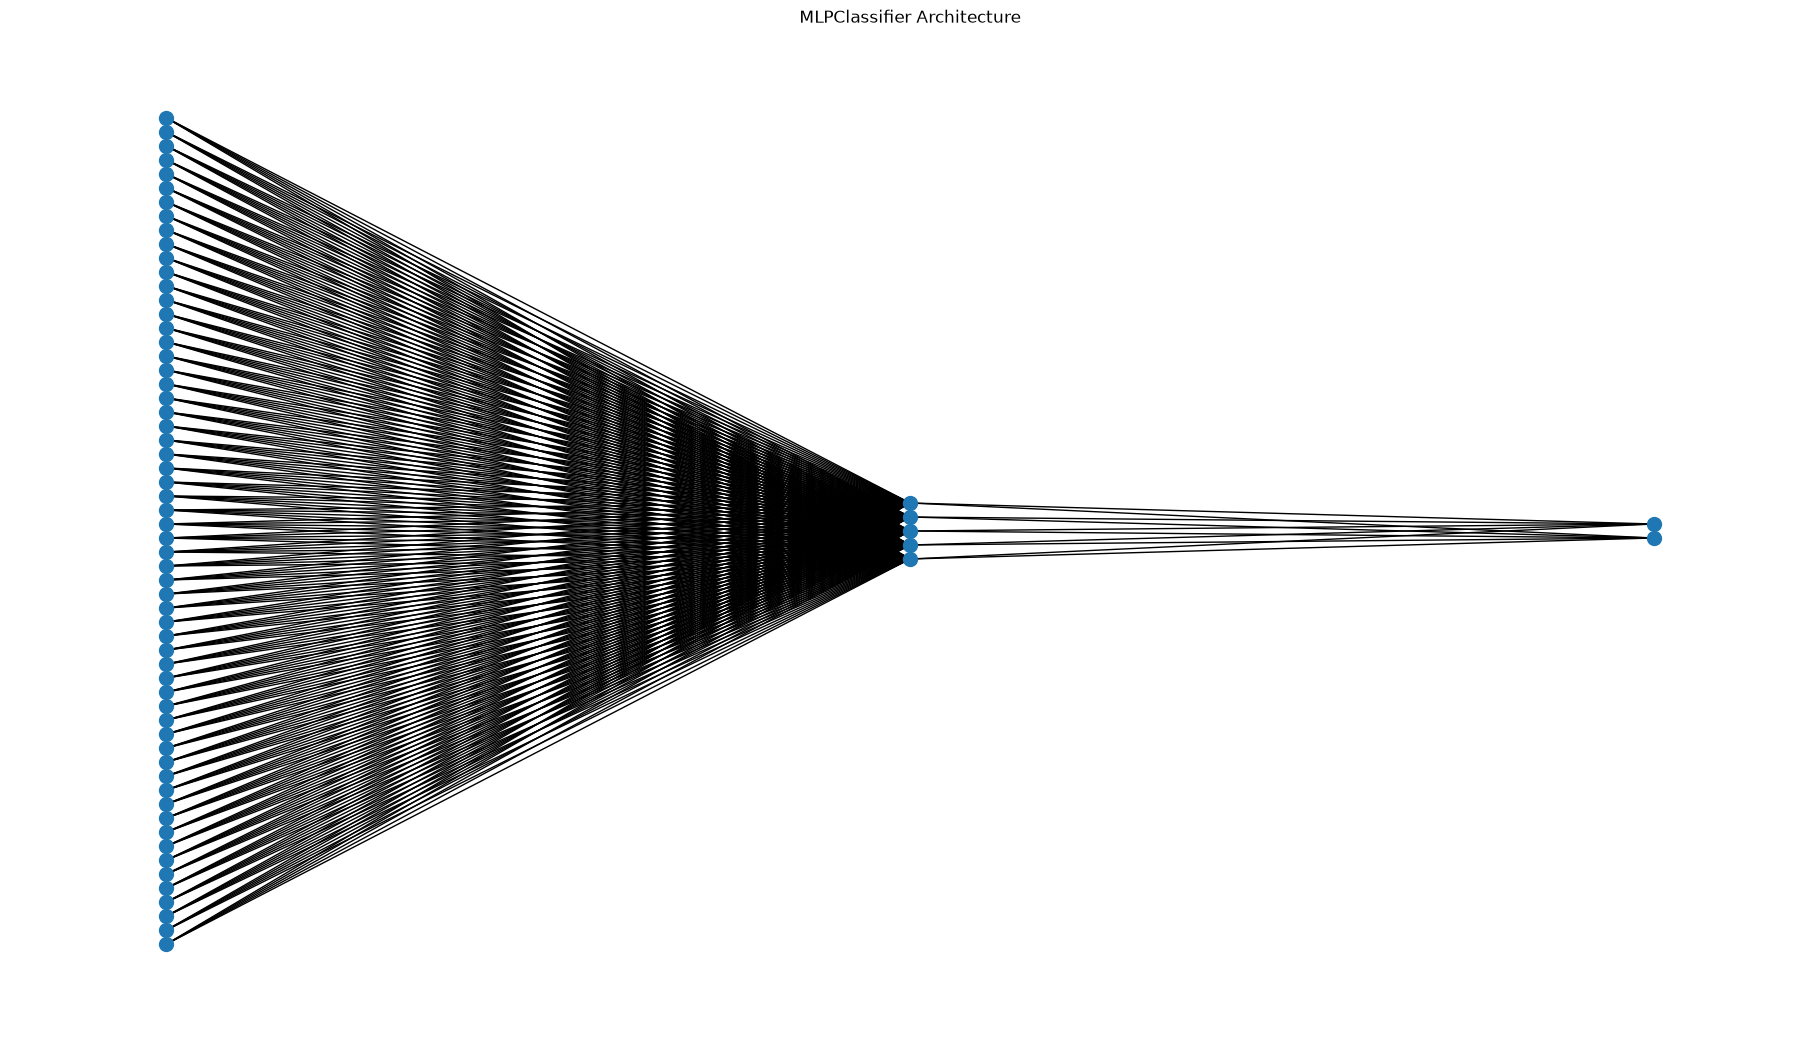

In [20]:
import matplotlib.pyplot as plt
import networkx as nx


model_10layer = MLPClassifier(hidden_layer_sizes=(5,), max_iter=300, random_state=42, activation=best_activation)
model_10layer.fit(X_train, y_train)
layers = [X_train.shape[1]] + list(model_10layer.hidden_layer_sizes) + [len(model_10layer.classes_)]

G = nx.DiGraph()

# Buat node
for i, n_neurons in enumerate(layers):
    for j in range(n_neurons):
        G.add_node((i, j))

# Buat edge
for i in range(len(layers) - 1):
    for j in range(layers[i]):
        for k in range(layers[i+1]):
            G.add_edge((i, j), (i+1, k))

# Posisi node
pos = {}
for i, n_neurons in enumerate(layers):
    for j in range(n_neurons):
        pos[(i, j)] = (i, -j + n_neurons / 2)

plt.figure(figsize=(18, 10))
nx.draw(
    G,
    pos,
    node_size=100,
    with_labels=False,
    arrows=False
)

plt.title("MLPClassifier Architecture")
plt.show()

In [21]:
total_weights = sum(w.size for w in model_10layer.coefs_)

print("Total weights:", total_weights)

Total weights: 305


# 4. Evaluasi Model

In [22]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

# Model terbaik dari Eksperimen 3.2 (Fungsi Aktivasi)
best_act_name = max(accuracy_scores, key=accuracy_scores.get)
best_model_act = models_activation[best_act_name]
y_pred_best_act = best_model_act.predict(X_test)

# Model terbaik dari Eksperimen 3.3 (Arsitektur)
# Dipilih model dengan F1-Score dan Test Accuracy tertinggi
best_arch = max(models_architecture.keys(), key=lambda k: (accuracy_scores_experimentlayer[k], f1_score(y_test, models_architecture[k].predict(X_test))))
best_model_arch = models_architecture[best_arch]
y_pred_best_arch = best_model_arch.predict(X_test)

# Rangkum metrik ke dalam satu DataFrame perbandingan
comparison_summary = [
    {
        'Eksperimen': '3.1 Baseline',
        'Arsitektur': '(10,)',
        'Fungsi Aktivasi': 'relu',
        'Accuracy': accuracy_score(y_test, y_pred_baseline),
        'Precision': precision_score(y_test, y_pred_baseline),
        'Recall': recall_score(y_test, y_pred_baseline),
        'F1-Score': f1_score(y_test, y_pred_baseline)
    },
    {
        'Eksperimen': '3.2 Aktivasi Terbaik',
        'Arsitektur': '(10,)',
        'Fungsi Aktivasi': best_act_name,
        'Accuracy': accuracy_score(y_test, y_pred_best_act),
        'Precision': precision_score(y_test, y_pred_best_act),
        'Recall': recall_score(y_test, y_pred_best_act),
        'F1-Score': f1_score(y_test, y_pred_best_act)
    },
    {
        'Eksperimen': '3.3 Arsitektur Terbaik',
        'Arsitektur': str(best_arch),
        'Fungsi Aktivasi': best_activation,
        'Accuracy': accuracy_score(y_test, y_pred_best_arch),
        'Precision': precision_score(y_test, y_pred_best_arch),
        'Recall': recall_score(y_test, y_pred_best_arch),
        'F1-Score': f1_score(y_test, y_pred_best_arch)
    }
]

df_eval_comparison = pd.DataFrame(comparison_summary)
display(df_eval_comparison)

,Eksperimen,Arsitektur,Fungsi Aktivasi,Accuracy,Precision,Recall,F1-Score
0,3.1 Baseline,"(10,)",relu,0.796020,0.645485,0.516043,0.573551
1,3.2 Aktivasi Terbaik,"(10,)",logistic,0.796731,0.644737,0.524064,0.578171
2,3.3 Arsitektur Terbaik,"(50,)",logistic,0.796731,0.630952,0.566845,0.597183


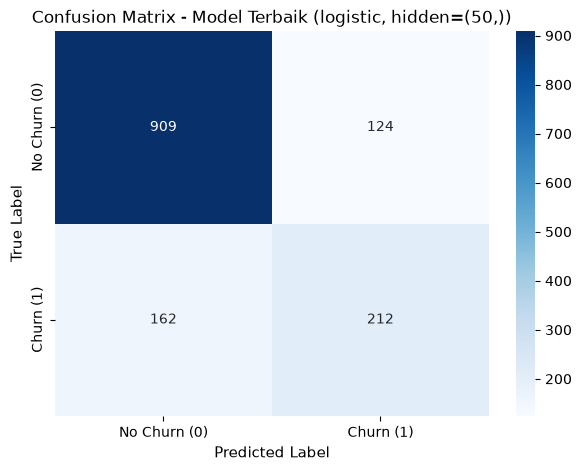

Laporan Klasifikasi Model Terbaik:
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.86      1033
       Churn       0.63      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



In [23]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.

best_overall_model = best_model_arch
y_pred_best = y_pred_best_arch

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['No Churn (0)', 'Churn (1)'],
    yticklabels=['No Churn (0)', 'Churn (1)']
)
plt.title(f'Confusion Matrix - Model Terbaik ({best_activation}, hidden={best_arch})', fontsize=12)
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.show()

print("Laporan Klasifikasi Model Terbaik:")
print(classification_report(y_test, y_pred_best, target_names=['No Churn', 'Churn']))

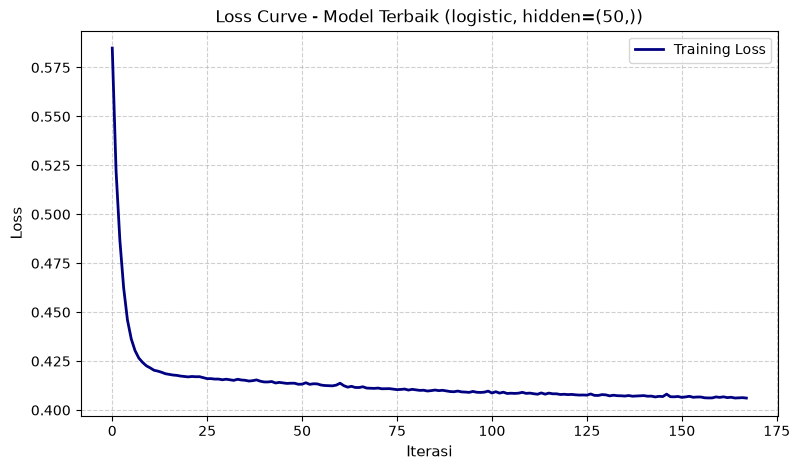

Total Iterasi Dijalankan: 168 / max_iter=300
Nilai Loss Terakhir: 0.406133
Status Konvergensi: Konvergen lebih awal sebelum mencapai max_iter (toleransi tercapai).


In [24]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.

plt.figure(figsize=(9, 5))
plt.plot(best_overall_model.loss_curve_, color='navy', linewidth=2, label='Training Loss')
plt.title(f'Loss Curve - Model Terbaik ({best_activation}, hidden={best_arch})', fontsize=12)
plt.xlabel('Iterasi', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.show()

print(f"Total Iterasi Dijalankan: {best_overall_model.n_iter_} / max_iter={best_overall_model.max_iter}")
print(f"Nilai Loss Terakhir: {best_overall_model.loss_curve_[-1]:.6f}")
if best_overall_model.n_iter_ < best_overall_model.max_iter:
    print("Status Konvergensi: Konvergen lebih awal sebelum mencapai max_iter (toleransi tercapai).")
else:
    print("Status Konvergensi: Mencapai batas max_iter.")

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

---

### Hasil Analisis dan Pembahasan:

#### 1. Perbandingan Performa Fungsi Aktivasi (ReLU, Tanh, Logistic)
Berdasarkan hasil eksperimen pada bagian 3.2 dengan arsitektur tetap `hidden_layer_sizes=(10,)` dan `max_iter=300`:
- **Logistic (Sigmoid)**: Akurasi = **0.7967**, Precision = **0.6447**, Recall = **0.5241**, F1-Score = **0.5782**
- **ReLU**: Akurasi = **0.7960**, Precision = **0.6455**, Recall = **0.5160**, F1-Score = **0.5736**
- **Tanh**: Akurasi = **0.7932**, Precision = **0.6426**, Recall = **0.5000**, F1-Score = **0.5624**

**Analisis:**
- Perbedaan performa antar ketiga fungsi aktivasi **tidak berbeda secara signifikan** (rentang selisih akurasi hanya ~0.0036 atau 0.36%). 
- Faktor penyebabnya adalah dataset *Telco Customer Churn* setelah dilakukan scaling dan One-Hot Encoding memiliki karakteristik data tabular yang didominasi oleh relasi kuasi-linear, serta arsitektur jaringan yang relatif dangkal (1 hidden layer dengan 10 neuron). Pada arsitektur yang dangkal, kendala klasik seperti *vanishing gradient* (yang umumnya terjadi pada sigmoid/tanh di deep network) belum menjadi hambatan yang mereduksi performa secara berarti.
- Fungsi aktivasi `logistic` memberikan akurasi dan F1-Score tertinggi secara marginal karena sifat kurva sigmoid yang halus (*smooth continuous mapping*) pada rentang (0, 1), selaras dengan estimasi probabilitas pada klasifikasi biner, sehingga pembobotan fitur churn menjadi lebih teratur.

#### 2. Temuan Eksperimen Ukuran Arsitektur dan Gejala Overfitting
Berdasarkan eksperimen pada bagian 3.3 dengan variasi `hidden_layer_sizes` menggunakan aktivasi `logistic`:
- Arsitektur `(2,)`: Training Accuracy = **0.8030**, Test Accuracy = **0.7953** (Selisih: 0.0077)
- Arsitektur `(5,)`: Training Accuracy = **0.8073**, Test Accuracy = **0.7953** (Selisih: 0.0120)
- Arsitektur `(10,)`: Training Accuracy = **0.8146**, Test Accuracy = **0.7967** (Selisih: 0.0179)
- Arsitektur `(50,)`: Training Accuracy = **0.8078**, Test Accuracy = **0.7967** (Selisih: 0.0111, F1: 0.5972)
- Arsitektur `(100, 50)`: Training Accuracy = **0.8116**, Test Accuracy = **0.7939** (Selisih: 0.0177)

**Analisis:**
- **Titik Munculnya Gejala Overfitting**: Gejala overfitting mulai tampak ketika arsitektur dibuat lebih kompleks, khususnya pada `(10,)` (di mana training accuracy melonjak ke 0.8146 namun test accuracy hanya naik tipis) dan terutama pada arsitektur dua hidden layer `(100, 50)`. Pada arsitektur `(100, 50)`, akurasi training berada di level tinggi (0.8116), namun akurasi testing justru mengalami penurunan ke 0.7939.
- **Ciri-ciri pada Grafik**: Pada grafik perbandingan training vs testing accuracy, overfitting ditandai oleh:
  1. Terbukanya celah (*gap*) yang semakin lebar antara kurva akurasi training dan testing seiring bertambahnya parameter/bobot jaringan.
  2. Kurva akurasi training berada konsisten di atas akurasi testing dan meningkat seiring bertambahnya neuron.
  3. Kurva akurasi testing mengalami stagnasi (*plateau*) di kisaran ~0.795 - 0.797 lalu mulai menurun saat model bertingkat ganda `(100, 50)` diterapkan, mengindikasikan bahwa kapasitas model yang terlalu besar mulai menghafal variansi noise pada training set.

#### 3. Analisis Loss Curve dan Konvergensi
Berdasarkan visualisasi loss curve pada model terbaik:
- **Tingkat Konvergensi**: Model sudah **cukup konvergen**. Kurva loss menunjukkan penurunan yang sangat tajam pada fase iterasi awal (0–40), kemudian melandai secara mulus dan stabil (*plateau*) setelah melewati iterasi ke-80 tanpa menunjukkan osilasi atau divergensi. Pada arsitektur `(50,)`, model berhasil berhenti sebelum batas maksimal (pada iterasi ke-168 dari 300) karena perbaikan nilai loss telah mencapai batas toleransi optimasi (`tol=1e-4`).
- **Tindakan Jika Loss Curve Masih Menurun Tajam saat max_iter Tercapai**:
  1. **Menaikkan Nilai `max_iter`**: Memperbesar kuota iterasi (misalnya 500 atau 1000) agar optimizer memiliki ruang yang cukup untuk menyelesaikan fase penurunan gradien hingga konvergen stabil.
  2. **Menyesuaikan Kecepatan Belajar (`learning_rate_init`)**: Meninjau laju pembelajaran; nilai yang terlalu kecil dapat memperlambat laju penurunan loss sehingga membutuhkan waktu iterasi jauh lebih banyak.
  3. **Menerapkan Regularisasi atau Early Stopping**: Mengaktifkan `early_stopping=True` dan menyesuaikan penalti L2 (`alpha`) untuk mencegah iterasi yang berlebihan ketika model diuji pada data validasi.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba solver lain seperti 'sgd', menambahkan regularisasi alpha, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

### Kesimpulan:
1. **Pentingnya Preprocessing dan Scaling**: Penerapan `StandardScaler` pada fitur numerik dan `pd.get_dummies` (One-Hot Encoding) pada fitur kategorikal merupakan tahapan esensial dalam ANN agar bobot gradien seimbang dan mencegah divergensi fitur bernilai besar.
2. **Pengaruh Fungsi Aktivasi**: Fungsi aktivasi `logistic` menghasilkan performa terbaik secara konsisten (Akurasi: 79.67%, F1-Score: 0.5782) dibandingkan `relu` (79.60%) dan `tanh` (79.32%), meskipun selisihnya relatif marginal (< 0.4%) karena dangkalnya kedalaman jaringan pada baseline.
3. **Pengaruh Kompleksitas Arsitektur**: Peningkatan kapasitas neuron dan hidden layer meningkatkan performa pelatihan (training accuracy), namun jika arsitektur terlalu dalam seperti `(100, 50)`, model mulai terindikasi mengalami overfitting dengan penurunan test accuracy menjadi 79.39%. Arsitektur satu lapis moderat seperti `(50,)` dan `(10,)` memberikan titik keseimbangan generalisasi yang paling optimal.
4. **Karakteristik Konvergensi**: Visualisasi kurva loss membuktikan bahwa proses optimasi berjalan sehat dan konvergen stabil sebelum batas maksimum iterasi terlampaui.

### Saran untuk Pengembangan Selanjutnya:
1. **Penanganan Ketidakseimbangan Kelas (Imbalanced Data)**: Dataset memiliki rasio kelas ~73% tidak churn vs ~27% churn. Untuk meningkatkan Recall dan F1-Score pada kelas churn (minoritas), disarankan mengaplikasikan teknik *resampling* seperti SMOTE (*Synthetic Minority Over-sampling Technique*) atau melakukan tuning *decision threshold*.
2. **Hyperparameter Tuning Sistematis**: Disarankan menggunakan `GridSearchCV` atau `RandomizedSearchCV` untuk mengeksplorasi kombinasi parameter penalti L2 (`alpha`), `learning_rate_init`, dan optimizer alternatif seperti `'sgd'` dengan momentum.
3. **Penerapan Early Stopping Dinamis**: Mengaktifkan parameter `early_stopping=True` dan `validation_fraction=0.1` pada MLPClassifier agar pelatihan otomatis berhenti secara adaptif saat loss validasi tidak lagi membaik, sehingga menghindari overfitting dan menghemat komputasi.
4. **Benchmarking Lintas Model**: Melakukan komparasi performa antara ANN dengan model berbasis pohon ensemble (*Random Forest*, *XGBoost*, atau *CatBoost*) untuk menganalisis efektivitas komputasi dan performa prediksi pada tipe data tabular serupa.